# Partie 1 – Récupération, nettoyage et enrichissement des données ESS11

Ce notebook part du fichier brut ESS11 (https://ess.sikt.no/en/datafile/242aaa39-3bbb-40f5-98bf-bfb1ce53d8ef), l'enrichit avec d'autres bases de données et produit :

1. une **heatmap des valeurs manquantes** par pays et par variable, qui permet de choisir les variables ou les pays à exclure 
2. un **retraitement des données** : codes de non-réponse (NaN), recodage, normalisation sur [0, 1], renommage, conversion des types 
3. de **nouvelles variables politiques** : `lrscale`, `lrscaleabs` et `politiscale`, ainsi que des groupes thématiques 
4. un **enrichissement** : partis votés (PartyFacts + ParlGov) et données pays (API Eurostat). Cela permet d'enrichir la base de données publique ESS11
5. un **fichier propre** `output/ess11_propre.csv` et un dictionnaire des variables

### Fichiers de données

Les fichiers sont publics, dans le bucket personnel de gleguestensae

- `ESS11e04_2.csv` : fichier intégré ESS11, édition 4.2 (https://ess.sikt.no/en/datafile/242aaa39-3bbb-40f5-98bf-bfb1ce53d8ef)
- `essprt-all.csv` : table PartyFacts des partis de l'ESS (https://github.com/hdigital/partyfactsdata/blob/main/import/essprtv/essprt-all.csv)
- `partyfacts-external-parties.csv` : table de liens de PartyFacts entre toutes les bases de partis (page *Download* du site PartyFacts, fichier external parties)
- `view_party.csv` : table des partis de ParlGov (https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/2VZ5ZC)

## 0. Installation, imports et configuration

In [1]:
# Package non fourni par défaut sur Onyxia : à exécuter une fois
%pip install --quiet eurostat

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re
import urllib.error
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Les résultats sont stockés dans `data/` pour les données brutes et externes, `output/` pour les résultats.

In [3]:
RACINE = Path.cwd()
CHEMIN_ESS = RACINE / "data" / "ESS11e04_2.csv"
DOSSIER_EXTERNES = RACINE / "data" / "externes"
DOSSIER_SORTIE = RACINE / "output"
DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)

ANNEE_REFERENCE = 2023   
ROUND_ESS = 11           # Utile pour les identifiants PartyFacts

### Récupération des fichiers 

Les datas sont en public sur Onyxia, on part donc du principe que le code est exécuté depuis un de ces serveurs : sinon, il faut manuellement importer les datas ( qui sont fournies en pièce jointe du mail, github limitant à 25 Mo ). 

Une solution plus générale est complexe à mettre en place : nous ne disposons pas des permissions d'accès au fichier `diffusion/` d'Onyxia, et les données de l'ESS11 sont en téléchargement libre, pas en accès libre.

In [4]:
BUCKET = "gleguestensae"
URL_DIFFUSION = f"https://minio.lab.sspcloud.fr/{BUCKET}"

FICHIERS = {
    "ESS11e04_2.csv": CHEMIN_ESS,
    "essprt-all.csv": DOSSIER_EXTERNES / "essprt-all.csv",
    "partyfacts-external-parties.csv": DOSSIER_EXTERNES / "partyfacts-external-parties.csv",
    "view_party.csv": DOSSIER_EXTERNES / "view_party.csv",
}


def recuperer_donnees():
    for nom, local in FICHIERS.items():
        if local.exists():
            print(f"Déjà présent : {local.relative_to(RACINE)}")
            continue
        local.parent.mkdir(parents=True, exist_ok=True)
        url = f"{URL_DIFFUSION}/{nom}"
        try:
            urllib.request.urlretrieve(url, local)
            print(f"Téléchargé : {nom} = {local.relative_to(RACINE)}")
        except (urllib.error.HTTPError, urllib.error.URLError) as e:
            print(f"Échec du téléchargement de {url} : {e}")


recuperer_donnees()

Déjà présent : data/ESS11e04_2.csv
Déjà présent : data/externes/essprt-all.csv
Déjà présent : data/externes/partyfacts-external-parties.csv
Déjà présent : data/externes/view_party.csv


## 1. Chargement des données

In [5]:
#Charge le CSV ESS et met les noms de colonnes en minuscules.

def charger_ess(chemin):
    df = pd.read_csv(chemin, low_memory=False)
    df.columns = df.columns.str.strip().str.lower()
    df["cntry"] = df["cntry"].astype("string").str.upper().str.strip()
    print(f"{len(df):,} répondants, {df.shape[1]} colonnes, {df['cntry'].nunique()} pays")
    return df


brut = charger_ess(CHEMIN_ESS)

50,116 répondants, 691 colonnes, 30 pays


## 2. Dictionnaire des variables

On ne garde que les variables qui se rangent dans des groupes pertinants : le questionnaire ESS11 comporte énormément de questions subsidiaires auxquelles nous ne nous intéresserons pas dans cette étude.

On retravaille chaque variable ESS :
- `nom` : nouveau nom lisible 
- `vmin`, `vmax` : bornes valides de l'échelle. Tout ce qui est en dehors (7/8/9, 77/88/99, 55, 6666...) correspond à un code de non-réponse et devient NaN (Dans ESS11, les codes de non réponse varient)
- `inverser` : `True` si l'échelle doit être retournée pour qu'une valeur haute ait le sens indiqué en commentaire de chaque groupe ( Utile dans la seconde partie : il est important qu'une valeur élevée pour une variable soit systématiquement associée à un profil "favorable au changement", dans l'ordre des groupes : plus favorable à l'immigration / plus libéral / plus égalitaire / plus préoccupé par le climat / plus confiant / plus satisfait / plus religieux / en meilleure santé / plus politisé)
- `groupe` : groupe thématique 

`lrscale` reste sur son échelle d'origine : 0 = gauche, 10 = droite.

In [6]:
VARIABLES = {
    #Immigration (haut = favorable à l'immigration)
    "imsmetn": dict(nom="immig_meme_ethnie",  vmin=1, vmax=4,  inverser=True,  groupe="immigration"),
    "imdfetn": dict(nom="immig_autre_ethnie", vmin=1, vmax=4,  inverser=True,  groupe="immigration"),
    "impcntr": dict(nom="immig_pays_pauvres", vmin=1, vmax=4,  inverser=True,  groupe="immigration"),
    "imbgeco": dict(nom="immig_economie",     vmin=0, vmax=10, inverser=False, groupe="immigration"),
    "imueclt": dict(nom="immig_culture",      vmin=0, vmax=10, inverser=False, groupe="immigration"),
    "imwbcnt": dict(nom="immig_pays_meilleur",vmin=0, vmax=10, inverser=False, groupe="immigration"),
    #LGBT / mœurs (haut = plus libéral)
    "freehms":  dict(nom="lgbt_libre",          vmin=1, vmax=5, inverser=True,  groupe="lgbt_moeurs"),
    "hmsfmlsh": dict(nom="lgbt_pas_honte",      vmin=1, vmax=5, inverser=False, groupe="lgbt_moeurs"),
    "hmsacld":  dict(nom="lgbt_adoption",       vmin=1, vmax=5, inverser=True,  groupe="lgbt_moeurs"),
    #Redistribution (haut = favorable à la redistribution)
    "gincdif": dict(nom="redistrib_reduire_inegalites", vmin=1, vmax=5, inverser=True, groupe="redistribution"),
    #Écologie (haut = plus préoccupé / engagé)
    "ccnthum": dict(nom="eco_cause_humaine",     vmin=1, vmax=5,  inverser=False, groupe="ecologie"),
    "ccrdprs": dict(nom="eco_responsabilite",    vmin=0, vmax=10, inverser=False, groupe="ecologie"),
    "wrclmch": dict(nom="eco_inquietude",        vmin=1, vmax=5,  inverser=False, groupe="ecologie"),
    #Confiance institutionnelle (haut = confiance)
    "trstprl": dict(nom="confiance_parlement",   vmin=0, vmax=10, inverser=False, groupe="confiance_institutionnelle"),
    "trstlgl": dict(nom="confiance_justice",     vmin=0, vmax=10, inverser=False, groupe="confiance_institutionnelle"),
    "trstplc": dict(nom="confiance_police",      vmin=0, vmax=10, inverser=False, groupe="confiance_institutionnelle"),
    "trstplt": dict(nom="confiance_politiciens", vmin=0, vmax=10, inverser=False, groupe="confiance_institutionnelle"),
    "trstprt": dict(nom="confiance_partis",      vmin=0, vmax=10, inverser=False, groupe="confiance_institutionnelle"),
    "trstep":  dict(nom="confiance_parl_europeen", vmin=0, vmax=10, inverser=False, groupe="confiance_institutionnelle"),
    "trstun":  dict(nom="confiance_onu",         vmin=0, vmax=10, inverser=False, groupe="confiance_institutionnelle"),
    #Europe (haut = pour plus d'intégration)
    "euftf": dict(nom="europe_integration", vmin=0, vmax=10, inverser=False, groupe="europe"),
    #Satisfaction (haut = satisfait)
    "stfeco": dict(nom="satisf_economie",    vmin=0, vmax=10, inverser=False, groupe="satisfaction"),
    "stfgov": dict(nom="satisf_gouvernement",vmin=0, vmax=10, inverser=False, groupe="satisfaction"),
    "stfdem": dict(nom="satisf_democratie",  vmin=0, vmax=10, inverser=False, groupe="satisfaction"),
    #Religiosité (haut = plus religieux)
    "rlgdgr": dict(nom="relig_degre",       vmin=0, vmax=10, inverser=False, groupe="religiosite"),
    "rlgatnd":dict(nom="relig_assiduite",   vmin=1, vmax=7,  inverser=True,  groupe="religiosite"),
    "pray":   dict(nom="relig_priere",      vmin=1, vmax=7,  inverser=True,  groupe="religiosite"),
    #Santé (haut = meilleure santé physique et mentale)
    "health":  dict(nom="sante_auto_evaluee", vmin=1, vmax=5, inverser=True,  groupe="sante"),
    "hlthhmp": dict(nom="sante_pas_genee",    vmin=1, vmax=3, inverser=False, groupe="sante"),
    #Santé mentale (haut = pas de problèmes de santé mentale)
    "fltdpr":  dict(nom="sante_pas_deprime",     vmin=1, vmax=4, inverser=True,  groupe="sante"),
    "flteeff": dict(nom="sante_pas_effort",      vmin=1, vmax=4, inverser=True,  groupe="sante"),
    "slprl":   dict(nom="sante_sommeil_calme",   vmin=1, vmax=4, inverser=True,  groupe="sante"),
    "wrhpp":   dict(nom="sante_heureux",         vmin=1, vmax=4, inverser=False, groupe="sante"),
    "fltlnl":  dict(nom="sante_pas_seul",        vmin=1, vmax=4, inverser=True,  groupe="sante"),
    "enjlf":   dict(nom="sante_profite_vie",     vmin=1, vmax=4, inverser=False, groupe="sante"),
    "fltsd":   dict(nom="sante_pas_triste",      vmin=1, vmax=4, inverser=True,  groupe="sante"),
    "cldgng":  dict(nom="sante_motive",          vmin=1, vmax=4, inverser=True,  groupe="sante"),
    #Genre (haut = plus égalitaire )
    "eqwrkbg": dict(nom="genre_emploi_egal_famille",  vmin=0, vmax=6, inverser=False, groupe="genre"),
    "eqmgmbg": dict(nom="genre_direction_egale",      vmin=0, vmax=6, inverser=False, groupe="genre"),
    "eqpaybg": dict(nom="genre_salaire_egal_eco",     vmin=0, vmax=6, inverser=False, groupe="genre"),
    "eqparep": dict(nom="genre_parite_parlement",     vmin=1, vmax=5, inverser=True,  groupe="genre"),
    "eqparlv": dict(nom="genre_conge_parental_egal",  vmin=1, vmax=5, inverser=True,  groupe="genre"),
    "freinsw": dict(nom="genre_licencier_insultes",   vmin=1, vmax=5, inverser=True,  groupe="genre"),
    "fineqpy": dict(nom="genre_amende_inegalite",     vmin=1, vmax=5, inverser=True,  groupe="genre"),
    "wsekpwr": dict(nom="genre_rejet_femmes_pouvoir", vmin=1, vmax=5, inverser=True,  groupe="genre"),
    "weasoff": dict(nom="genre_rejet_femmes_offensees", vmin=1, vmax=5, inverser=True, groupe="genre"),
    "wexashr": dict(nom="genre_rejet_harcelement_exagere", vmin=1, vmax=5, inverser=True, groupe="genre"),
    "wlespdm": dict(nom="genre_percoit_ecart_salaire", vmin=1, vmax=5, inverser=False, groupe="genre"),
    "wprtbym": dict(nom="genre_rejet_protection",     vmin=1, vmax=5, inverser=False, groupe="genre"),
    "wbrgwrm": dict(nom="genre_rejet_femmes_morales", vmin=1, vmax=5, inverser=False, groupe="genre_hors_indice"),

    #Variables politiques (hors groupes )
    "lrscale": dict(nom="lrscale", vmin=0, vmax=10, inverser=False, groupe="politique"),
    "polintr": dict(nom="pol_interet", vmin=1, vmax=4, inverser=True, groupe="politisation_interet"),
    # actions politiques : 1 = oui, 2 = non. Après inversion et normalisation, oui = 1
    "contplt":  dict(nom="pol_contact_elu",       vmin=1, vmax=2, inverser=True, groupe="politisation_participation"),
    "donprty":  dict(nom="pol_don_parti",         vmin=1, vmax=2, inverser=True, groupe="politisation_participation"),
    "badge":    dict(nom="pol_badge",             vmin=1, vmax=2, inverser=True, groupe="politisation_participation"),
    "sgnptit":  dict(nom="pol_petition",          vmin=1, vmax=2, inverser=True, groupe="politisation_participation"),
    "pbldmna":  dict(nom="pol_manifestation",     vmin=1, vmax=2, inverser=True, groupe="politisation_participation"),
    "bctprd":   dict(nom="pol_boycott",           vmin=1, vmax=2, inverser=True, groupe="politisation_participation"),
    "pstplonl": dict(nom="pol_post_en_ligne",     vmin=1, vmax=2, inverser=True, groupe="politisation_participation"),
    "volunfp":  dict(nom="pol_benevolat",         vmin=1, vmax=2, inverser=True, groupe="politisation_participation"),
    "vote":     dict(nom="pol_a_vote",            vmin=1, vmax=2, inverser=True, groupe="politisation_partisan"),
    "clsprty":  dict(nom="pol_proche_parti",      vmin=1, vmax=2, inverser=True, groupe="politisation_partisan"),
}

GROUPES_THEMATIQUES = [
    "immigration", "lgbt_moeurs", "redistribution", "ecologie",
    "confiance_institutionnelle", "europe", "satisfaction", "religiosite",
    "genre", "sante",
]

### Variables sociodémographiques

In [7]:
SOCIODEMO = {
    "agea":     ("age",15, 110),
    "yrbrn":    ("annee_naissance",1900,2012),
    "gndr":     ("genre_resp",1,2),     # 1 = homme, 2 = femme
    "eisced":   ("education_isced",1,7),     
    "eduyrs":   ("annees_etudes",0,40),
    "hinctnta": ("revenu_decile",1,10),
    "domicil":  ("lieu_vie",1,5),     # 1 = grande ville, 5 = isolé
}

POIDS = ["anweight", "pspwght", "pweight", "dweight"]
IDENTIFIANTS = ["idno", "cntry", "essround"]

## 3. Codes de non-réponse

Pour `lrscale`, on garde "ne sait pas" (code 88) dans une indicatrice `lrscale_nsp` : ne pas savoir se placer est un signe de faible politisation.

In [8]:
def colonnes_presentes(df, liste):
    presentes = [c for c in liste if c in df.columns]
    absentes = [c for c in liste if c not in df.columns]
    if absentes:
        warnings.warn(f"Variables absentes du fichier, ignorées : {absentes}")
    return presentes


def codes_manquants_vers_nan(df):
    df = df.copy()
    bornes = {k: (v["vmin"], v["vmax"]) for k, v in VARIABLES.items()}
    bornes.update({k: (vmin, vmax) for k, (_, vmin, vmax) in SOCIODEMO.items()})

    if "lrscale" in df.columns:
        lr_brut = pd.to_numeric(df["lrscale"], errors="coerce")
        df["lrscale_nsp"] = (lr_brut == 88).astype("Int8")

    for col in colonnes_presentes(df, list(bornes)):
        vmin, vmax = bornes[col]
        x = pd.to_numeric(df[col], errors="coerce")
        df[col] = x.where(x.between(vmin, vmax))
    return df


df = codes_manquants_vers_nan(brut)

## 4. Heatmap des valeurs manquantes par pays

Une case = part de répondants d'un pays sans réponse valide à une variable. L'objectif de cette section est de vérifier si certains pays ou certaines questions sont vides : on les retire alors.

In [9]:
def taux_manquants_par_pays(df,variables):
    variables = colonnes_presentes(df, variables)
    taux = df[variables].isna().groupby(df["cntry"]).mean()
    taux["MEAN"] = taux.mean(axis=1)
    return taux.sort_values("MEAN", ascending=False)


def heatmap_manquants(taux,chemin_png):
    fig, ax = plt.subplots(figsize=(max(12, 0.35 * taux.shape[1]), max(6, 0.35 * taux.shape[0])))
    sns.heatmap(taux, cmap="Reds", vmin=0, vmax=1, cbar_kws={"label": "Share of missing values"},
                linewidths=0.3, linecolor="white", ax=ax)
    ax.set_xlabel("ESS variable")
    ax.set_ylabel("Country (sorted by mean missing rate)")
    ax.set_title("ESS11: share of missing values by country and variable")
    plt.tight_layout()
    if chemin_png:
        fig.savefig(chemin_png, dpi=150)
        print(f"Heatmap enregistrée : {chemin_png}")
    return fig

Heatmap enregistrée : /home/onyxia/work/polarisation-ess11/partie1/output/heatmap_manquants.png


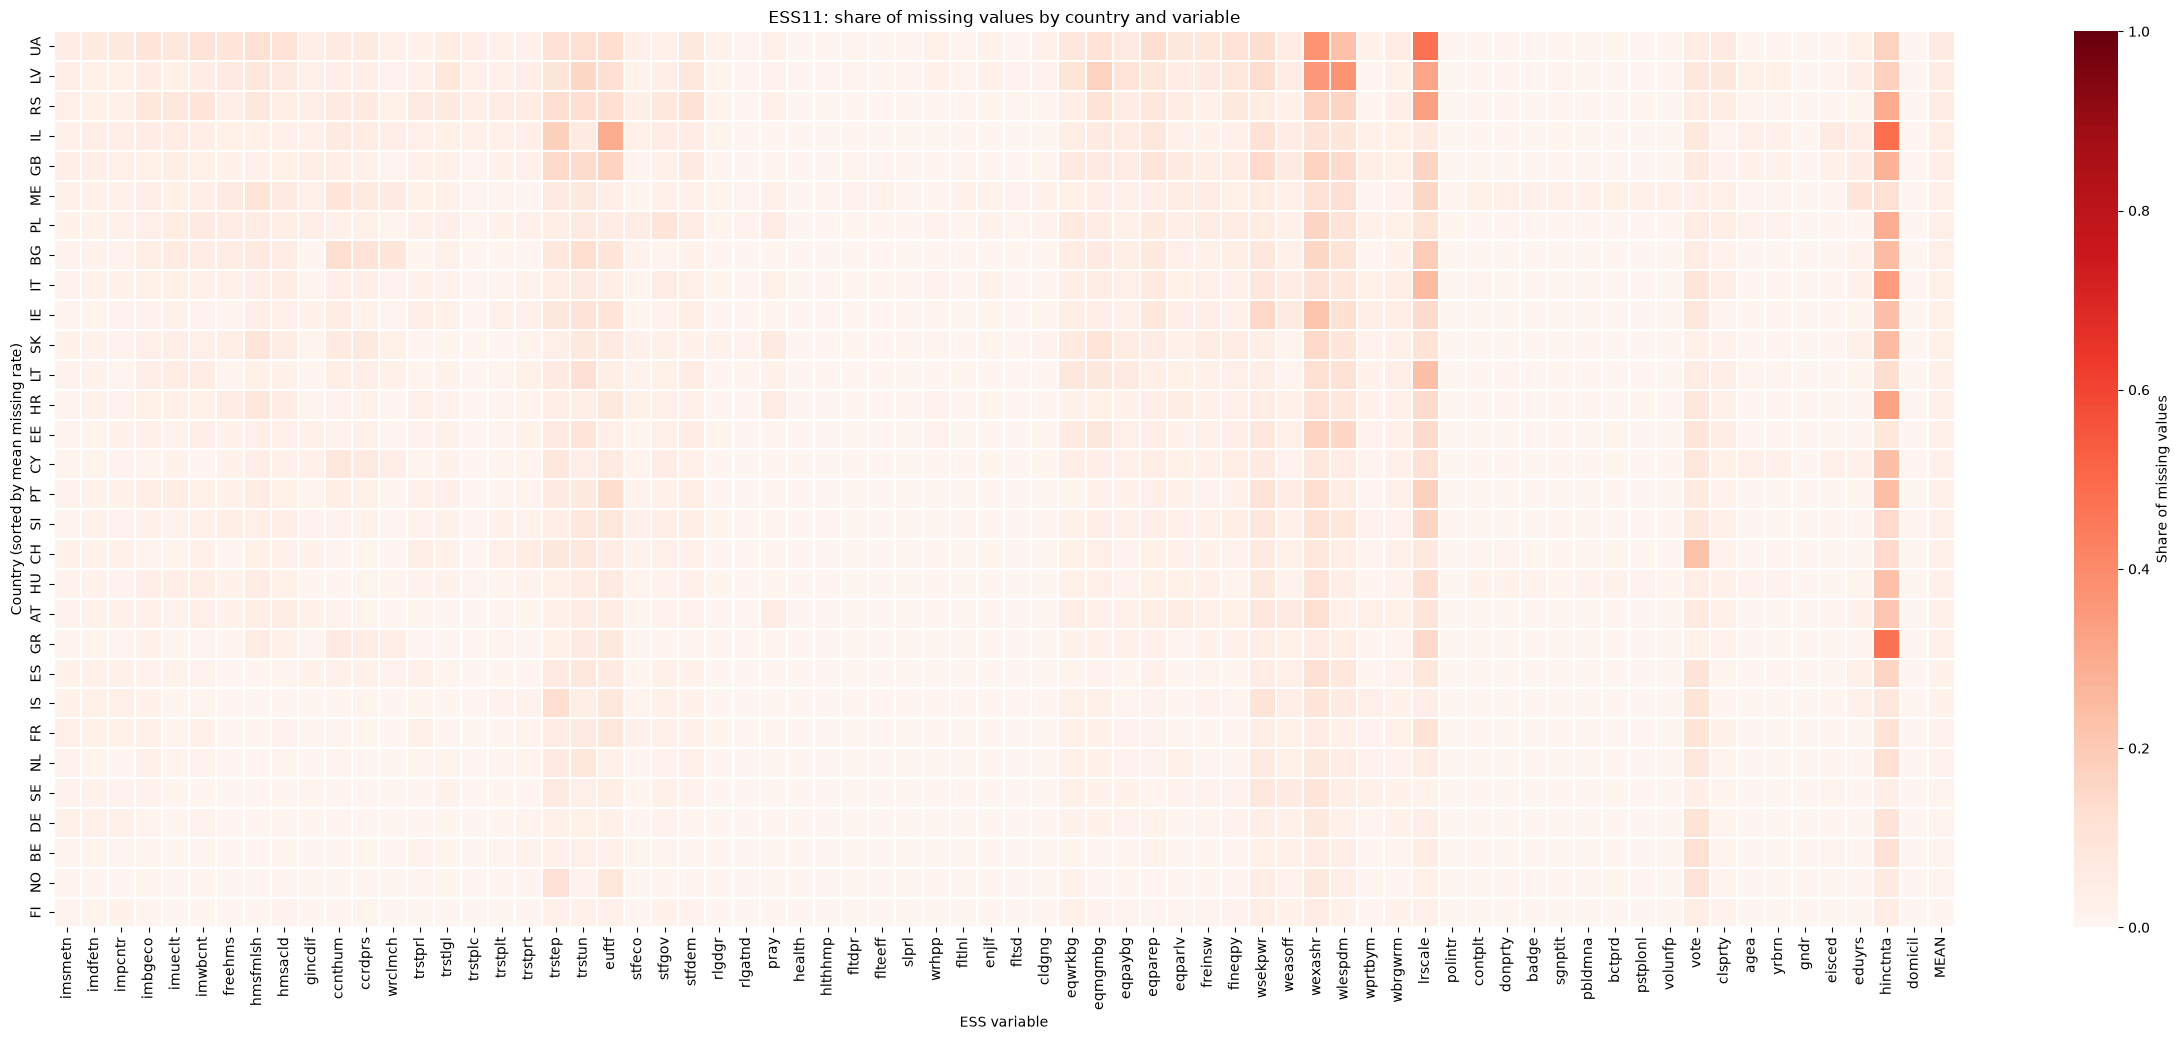

In [10]:
taux = taux_manquants_par_pays(df, list(VARIABLES) + list(SOCIODEMO))
taux.to_csv(DOSSIER_SORTIE / "taux_manquants_par_pays.csv")
heatmap_manquants(taux, DOSSIER_SORTIE / "heatmap_manquants.png")
plt.show()

Taux moyen de valeurs manquantes par pays :

In [11]:
taux["MEAN"].round(3)

cntry
UA    0.062
LV    0.057
RS    0.051
IL    0.044
GB    0.042
ME    0.037
PL    0.037
BG    0.036
IT    0.035
IE    0.034
SK    0.033
LT    0.031
HR    0.030
EE    0.029
CY    0.028
PT    0.028
SI    0.026
CH    0.025
HU    0.025
AT    0.025
GR    0.024
ES    0.021
IS    0.020
FR    0.019
NL    0.017
SE    0.015
DE    0.014
BE    0.013
NO    0.013
FI    0.011
Name: MEAN, dtype: float64

## 5. Exclusion de pays et de variables après analyse de la heatmap

Après analyse de la heatmap, il apparaît que tous les pays affichent, pour la plupart des variables, des taux de réponse satisfaisants, à l'exception de l'Ukraine. On l'exclut.
De plus, `hinctnta` est aussi une question faiblement répondue dans une majorité de pays : on l'exclue

On exclut également Israël, puisque le choix a été fait de se concentrer sur les pays européens.

In [12]:
PAYS_EXCLUS = ["UA", "IL"]


def exclure_pays(df, pays_exclus):
    n_avant = len(df)
    df = df[~df["cntry"].isin(pays_exclus)].copy()
    print(f"Pays exclus : {pays_exclus} -> {n_avant - len(df):,} répondants retirés, "
          f"{len(df):,} restants")
    return df


df = exclure_pays(df, PAYS_EXCLUS)


# Variables trop peu renseignées (voir la heatmap)
VARIABLES_EXCLUES = ["hinctnta"]


def exclure_variables(df, variables_exclues):
    """Retire les variables de la base et des dictionnaires utilisés dans la suite du notebook."""
    for v in variables_exclues:
        VARIABLES.pop(v, None)
        SOCIODEMO.pop(v, None)
    df = df.drop(columns=[v for v in variables_exclues if v in df.columns])
    print(f"Variables exclues : {variables_exclues}")
    return df


df = exclure_variables(df, VARIABLES_EXCLUES)

Pays exclus : ['UA', 'IL'] -> 3,567 répondants retirés, 46,549 restants
Variables exclues : ['hinctnta']


## 6. Recodage, normalisation, renommage

In [13]:
#Crée, pour chaque variable de VARIABLES, une colonne au nom lisible, normalisée sur [0, 1] et dans le sens défini plus haut. `lrscale` reste sur 0-10.
def recoder_et_normaliser(df):
    df = df.copy()
    for col in colonnes_presentes(df, list(VARIABLES)):
        p = VARIABLES[col]
        x = df[col].astype("Float64")
        if p["inverser"]:
            x = p["vmin"] + p["vmax"] - x
        if col == "lrscale":
            df["lrscale"] = x
        else:
            df[p["nom"]] = (x - p["vmin"]) / (p["vmax"] - p["vmin"])
    return df


def nettoyer_sociodemo(df):
    df = df.copy()
    presentes = colonnes_presentes(df, list(SOCIODEMO))
    df = df.rename(columns={k: SOCIODEMO[k][0] for k in presentes})

    if "genre_resp" in df:
        df["femme"] = (df["genre_resp"] == 2).astype("Int8").where(df["genre_resp"].notna())
    if "age" in df:
        df["tranche_age"] = pd.cut(df["age"], bins=[14, 29, 44, 59, 74, 120],
                                   labels=["15-29", "30-44", "45-59", "60-74", "75+"])
    if "annee_naissance" in df:
        decennie = (df["annee_naissance"] // 10 * 10).astype("Int64")
        df["cohorte"] = decennie.astype("string") + "s"
    if "lieu_vie" in df:
        df["urbain"] = (df["lieu_vie"] <= 2).astype("Int8").where(df["lieu_vie"].notna())
    if "cntry" in df:
        df["cntry"] = df["cntry"].astype("category")
    return df

In [14]:
df = recoder_et_normaliser(df)
df = nettoyer_sociodemo(df)

## 7. Variables politiques et indices thématiques

On crée de nouvelles variables afin de réaliser notre étude

- `lrscale` : positionnement gauche 0 / droite 10
- `lrscaleabs` = |lrscale − 5| : extrémité idéologique, de 0 (centre) à 5 (extrême) ;
- `politiscale` : indice de politisation sur [0, 1], moyenne de trois composantes :
  - intérêt pour la politique (`polintr`) 
  - participation : part des 8 actions politiques réalisées dans les 12 derniers mois 
  - lien partisan : a voté aux dernières élections, se sent proche d'un parti.

  L'indice est calculé si au moins 2 des 3 composantes sont disponibles.

Les indices thématiques `idx_<groupe>` sont la moyenne des items normalisés de chaque groupe, calculée si au moins la moitié des items sont renseignés.

In [15]:
def noms_du_groupe(groupe, df):
    return [p["nom"] for k, p in VARIABLES.items() if p["groupe"] == groupe and p["nom"] in df.columns]


def moyenne_lignes(df, cols, min_part=0.5):
    if not cols:
        return pd.Series(pd.NA, index=df.index, dtype="Float64")
    bloc = df[cols].astype("Float64")
    n_ok = bloc.notna().sum(axis=1)
    return bloc.mean(axis=1).where(n_ok >= np.ceil(min_part * len(cols)))


def creer_variables_politiques(df):
    df = df.copy()
    if "lrscale" in df:
        df["lrscaleabs"] = (df["lrscale"] - 5).abs()

    composantes = pd.DataFrame({
        "politi_interet": moyenne_lignes(df, noms_du_groupe("politisation_interet", df)),
        "politi_participation": moyenne_lignes(df, noms_du_groupe("politisation_participation", df)),
        "politi_partisan": moyenne_lignes(df, noms_du_groupe("politisation_partisan", df)),
    })
    df = pd.concat([df, composantes], axis=1)
    df["politiscale"] = moyenne_lignes(df, list(composantes.columns), min_part=2 / 3)
    return df

def creer_indices_thematiques(df):
    df = df.copy()
    for g in GROUPES_THEMATIQUES:
        cols = noms_du_groupe(g, df)
        if not cols:
            warnings.warn(f"Groupe « {g} » = aucune variable disponible, indice non créé.")
            continue
        df[f"idx_{g}"] = moyenne_lignes(df, cols)
    return df

In [16]:
df = creer_variables_politiques(df)
df = creer_indices_thematiques(df)

## 8. Enrichissement 1 : partis votés (PartyFacts + ParlGov)

On enrichit le dataset de deux autres bases de données, qui recense le positionnement politique des différents partis d'Europe (et leur alignement sur certains sujets): on peut donc utiliser le vote des répondants.

In [17]:

TOUR_RETENU = {"de": "2", "lt": "1"}   # DE : prtvgde2 (2e voix, liste) ; LT : prtvclt1 (1er vote, parti) : Dans ces pays on se limite à un tour de scrutin particulier

def construire_ess_id(df):
    cols_vote = [c for c in df.columns if re.fullmatch(r"prtv[a-z]*[a-z]{2}\d?", c)]
    ess_id = pd.Series(pd.NA, index=df.index, dtype="string")
    cntry = df["cntry"].astype("string").str.lower()

    for col in cols_vote:
        tour = col[-1] if col[-1].isdigit() else ""
        pays = col[-3:-1] if tour else col[-2:]
        if tour and TOUR_RETENU.get(pays) != tour:
            continue
        code = pd.to_numeric(df[col], errors="coerce")
        masque = (cntry == pays) & code.between(1, 65)   # 66/77/88/99 = sans objet / NSP / refus
        suffixe = f"-{pays}{tour}" if tour else ""
        ess_id[masque] = (pays.upper() + f"-{ROUND_ESS}-" +
                          code[masque].astype("Int64").astype("string") + "-v" + suffixe)
    print(f"Vote identifié pour {ess_id.notna().mean():.1%} des répondants "
          f"({len(cols_vote)} variables prtv* trouvées)")
    return ess_id


def lire_csv_externe(nom, colonnes_requises):
    chemin = DOSSIER_EXTERNES / nom
    if not chemin.exists():
        print(f"[PartyFacts] Fichier manquant : {chemin} = étape sautée.")
        return None
    t = pd.read_csv(chemin, low_memory=False)
    manquantes = set(colonnes_requises) - set(t.columns)
    if manquantes:
        raise KeyError(f"{nom} : colonnes {manquantes} introuvables. Colonnes disponibles : {list(t.columns)}")
    return t


def enrichir_partis(df):
    df = df.copy()
    df["parti_ess_id"] = construire_ess_id(df)

    essprt = lire_csv_externe("essprt-all.csv", ["ess_id"])
    liens = lire_csv_externe("partyfacts-external-parties.csv",
                             ["dataset_key", "dataset_party_id", "partyfacts_id"])
    parlgov = lire_csv_externe("view_party.csv", ["party_id", "family_name", "left_right"])
    if essprt is None or liens is None or parlgov is None:
        return df

    liens["dataset_party_id"] = liens["dataset_party_id"].astype("string")
    if "partyfacts_id" in essprt.columns:
        pf = essprt[["ess_id", "partyfacts_id"]]
    else:
        pf_ess = liens.loc[liens["dataset_key"] == "essprtv", ["dataset_party_id", "partyfacts_id"]]
        pf = essprt[["ess_id", "first_ess_id"]].astype("string").merge(
            pf_ess, left_on="first_ess_id", right_on="dataset_party_id", how="left"
        )[["ess_id", "partyfacts_id"]]
    pf = pf.dropna().drop_duplicates("ess_id").astype({"ess_id": "string", "partyfacts_id": "Int64"})

    pg_liens = (liens.loc[liens["dataset_key"] == "parlgov", ["partyfacts_id", "dataset_party_id"]]
                .rename(columns={"dataset_party_id": "parlgov_id"})
                .drop_duplicates("partyfacts_id"))
    pg_liens["parlgov_id"] = pd.to_numeric(pg_liens["parlgov_id"], errors="coerce").astype("Int64")
    pg_liens["partyfacts_id"] = pg_liens["partyfacts_id"].astype("Int64")

    cols_pg = {"party_id": "parlgov_id", "family_name": "parti_famille", "left_right": "parti_lr",
               "state_market": "parti_etat_marche", "liberty_authority": "parti_liberte_autorite",
               "eu_anti_pro": "parti_pro_ue"}
    pg = parlgov[[c for c in cols_pg if c in parlgov.columns]].rename(columns=cols_pg)
    pg["parlgov_id"] = pg["parlgov_id"].astype("Int64")

    table = pf.merge(pg_liens, on="partyfacts_id", how="left").merge(pg, on="parlgov_id", how="left")
    table = table.rename(columns={"ess_id": "parti_ess_id", "partyfacts_id": "parti_partyfacts_id"})

    n_avant = len(df)
    df = df.merge(table, on="parti_ess_id", how="left")
    assert len(df) == n_avant, "La jointure a dupliqué des lignes"
    a_vote = df["parti_ess_id"].notna()
    print(f"[PartyFacts] Parti relié à ParlGov pour {df.loc[a_vote, 'parti_lr'].notna().mean():.1%} "
          f"des votants identifiés")
    return df

In [18]:
df = enrichir_partis(df)

Vote identifié pour 60.7% des répondants (33 variables prtv* trouvées)
[PartyFacts] Parti relié à ParlGov pour 69.5% des votants identifiés


## 9. Enrichissement 2 : données pays via l'API Eurostat
 Le second enrichissement est tiré de l'API Eurostat, qui donne des données supplémentaires sur chaque pays : 
 
- PIB par habitant en standard de pouvoir d'achat : `tec00114` ;
- coefficient de Gini du revenu disponible : `ilc_di12` ;
- taux de chômage des 15-74 ans : `une_rt_a`.

Eurostat ne couvre pas Israël et le Royaume-Uni depuis 2020, et seulement en partie les pays candidats : leurs valeurs resteront NaN.

In [19]:
INDICATEURS_EUROSTAT = {
    "pib_hab_spa":   dict(code="tec00114", filtres={}),
    "gini": dict(code="ilc_di12", filtres={"age": "TOTAL"}),
    "taux_chomage":  dict(code="une_rt_a", filtres={"age": "Y15-74", "sex": "T", "unit": "PC_ACT"}),
}
ESS_VERS_EUROSTAT = {"GR": "EL", "GB": "UK"}   # codes pays qui diffèrent


def indicateur_eurostat(code, filtres, annee=ANNEE_REFERENCE):
    import eurostat
    brut = eurostat.get_data_df(code)
    col_geo = next(c for c in brut.columns if "geo" in c.lower())
    brut = brut.rename(columns={col_geo: "geo"})
    for dim, val in filtres.items():
        brut = brut[brut[dim] == val]

    annees = [c for c in brut.columns if re.fullmatch(r"\d{4}", str(c))]
    dims = [c for c in brut.columns if c not in annees + ["geo", "freq"]]
    if brut.duplicated("geo").any():
        valeurs = {d: brut[d].unique().tolist()[:10] for d in dims if brut[d].nunique() > 1}
        raise ValueError(f"{code} : plusieurs lignes par pays, fixez ces dimensions dans `filtres` : {valeurs}")

    serie = brut.set_index("geo")[str(annee)] if str(annee) in brut else pd.Series(dtype=float)
    if str(annee - 1) in brut:
        serie = serie.fillna(brut.set_index("geo")[str(annee - 1)])
    return pd.to_numeric(serie, errors="coerce")


def enrichir_eurostat(df):
    try:
        import eurostat  
    except ImportError:
        print("[Eurostat] Package `eurostat` non installé (pip install eurostat) = étape sautée.")
        return df

    pays = pd.DataFrame({"cntry": df["cntry"].astype("string").unique()})
    pays["geo"] = pays["cntry"].replace(ESS_VERS_EUROSTAT)
    for nom, p in INDICATEURS_EUROSTAT.items():
        try:
            pays[nom] = pays["geo"].map(indicateur_eurostat(p["code"], p["filtres"]))
        except Exception as e:  # API indisponible, dimension à préciser...
            print(f"[Eurostat] {nom} ({p['code']}) non récupéré : {e}")
    print("[Eurostat] Pays sans données :",
          pays.loc[pays.drop(columns=["cntry", "geo"]).isna().all(axis=1), "cntry"].tolist())

    pays = pays.drop(columns="geo")
    pays.to_csv(DOSSIER_SORTIE / "indicateurs_pays_eurostat.csv", index=False)
    df = df.copy()
    df["cntry"] = df["cntry"].astype("string")
    return df.merge(pays, on="cntry", how="left").astype({"cntry": "category"})

In [20]:
df = enrichir_eurostat(df)

[Eurostat] Pays sans données : []


Le PIB par habitant et le taux de chômage sont fournis pour d'éventuelles analyses au niveau pays (La polarisation est-elle plus forte dans les pays plus inégalitaires ou en difficulté économique,etc ?) ; ils ne sont pas exploités dans les parties 2 et 3.

## 10. Pondérations

On pondère avec `anweight`.

In [21]:
def moyenne_ponderee(x,poids):
    ok = x.notna() & poids.notna()
    return float(np.average(x[ok].astype(float), weights=poids[ok].astype(float)))

## 11. Dictionnaire des variables et export

In [22]:
def dictionnaire_variables(df):
    lignes = []
    for k, p in VARIABLES.items():
        if p["nom"] in df.columns:
            echelle = "0-10" if k == "lrscale" else "0-1"
            lignes.append(dict(variable=p["nom"], source_ess=k, groupe=p["groupe"],
                               echelle=echelle, inversee=p["inverser"]))
    derivees = {
        "lrscale_nsp": "1 si « ne sait pas » à lrscale",
        "lrscaleabs": "|lrscale - 5|, extrémité idéologique (0-5)",
        "politi_interet": "composante intérêt (0-1)",
        "politi_participation": "part des actions politiques réalisées (0-1)",
        "politi_partisan": "a voté / proche d'un parti (0-1)",
        "politiscale": "indice de politisation (0-1)",
        "parti_lr": "position gauche-droite du parti voté (ParlGov, 0-10)",
        "parti_famille": "famille du parti voté (ParlGov)",
    }
    derivees.update({f"idx_{g}": f"indice thématique {g} (0-1)" for g in GROUPES_THEMATIQUES})
    for v, d in derivees.items():
        if v in df.columns:
            lignes.append(dict(variable=v, source_ess="dérivée", groupe="", echelle=d, inversee=""))
    return pd.DataFrame(lignes)


def exporter(df, nom="ess11_propre"):
    chemin = DOSSIER_SORTIE / f"{nom}.csv"
    df.to_csv(chemin, index=False)
    print(f"Export : {chemin}")


def selection_colonnes_finales(df):
    colonnes = (
        colonnes_presentes(df, IDENTIFIANTS + POIDS)
        + [c for c in df.columns if c in {s[0] for s in SOCIODEMO.values()}
           or c in {"femme", "tranche_age", "cohorte", "urbain"}]
        + ["lrscale", "lrscale_nsp", "lrscaleabs", "politi_interet", "politi_participation",
           "politi_partisan", "politiscale"]
        + [p["nom"] for k, p in VARIABLES.items() if k != "lrscale" and p["nom"] in df.columns]
        + [c for c in df.columns if c.startswith("idx_")]
        + [c for c in df.columns if c.startswith("parti_")]
        + [c for c in INDICATEURS_EUROSTAT if c in df.columns]
    )
    return list(dict.fromkeys(c for c in colonnes if c in df.columns))

In [23]:
propre = df[selection_colonnes_finales(df)]
exporter(propre)
dictionnaire_variables(propre).to_csv(DOSSIER_SORTIE / "dictionnaire_variables.csv", index=False)
print(f"Base finale : {propre.shape[0]:,} répondants, {propre.shape[1]} variables")
propre.head()

Export : /home/onyxia/work/polarisation-ess11/partie1/output/ess11_propre.csv
Base finale : 46,549 répondants, 105 variables


,idno,cntry,essround,anweight,pspwght,pweight,dweight,genre_resp,annee_naissance,age,...,parti_ess_id,parti_partyfacts_id,parti_famille,parti_lr,parti_etat_marche,parti_liberte_autorite,parti_pro_ue,pib_hab_spa,gini,taux_chomage
0,50014,AT,11,0.130013,0.392891,0.330915,1.185115,1,1958.0,65.0,...,AT-11-1-v,1384,Social democracy,3.7293,3.4728,3.4766,8.4495,121.0,28.1,5.1
1,50030,AT,11,0.107598,0.325153,0.330915,0.609898,2,2002.0,21.0,...,AT-11-5-v,1659,Green/Ecologist,2.4604,2.7489,1.4308,6.6845,121.0,28.1,5.1
2,50057,AT,11,1.323666,4.000023,0.330915,1.392330,2,1970.0,53.0,...,AT-11-5-v,1659,Green/Ecologist,2.4604,2.7489,1.4308,6.6845,121.0,28.1,5.1
3,50106,AT,11,0.058316,0.176228,0.330915,0.556062,2,1945.0,78.0,...,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,121.0,28.1,5.1
4,50145,AT,11,0.351080,1.060940,0.330915,0.722795,1,1959.0,64.0,...,AT-11-5-v,1659,Green/Ecologist,2.4604,2.7489,1.4308,6.6845,121.0,28.1,5.1


## 12. Statistiques descriptives de la base finale

Le tableau produit contient les pourcentages de réponses valides pour les principales variables de l'étude

In [25]:

NOMS_PAYS = {
    "AT": "Autriche", "BE": "Belgique", "BG": "Bulgarie", "CH": "Suisse", "CY": "Chypre",
    "DE": "Allemagne", "EE": "Estonie", "ES": "Espagne", "FI": "Finlande", "FR": "France",
    "GB": "Royaume-Uni", "GR": "Grèce", "HR": "Croatie", "HU": "Hongrie", "IE": "Irlande",
    "IS": "Islande", "IT": "Italie", "LT": "Lituanie", "LV": "Lettonie", "ME": "Monténégro",
    "NL": "Pays-Bas", "NO": "Norvège", "PL": "Pologne", "PT": "Portugal", "RS": "Serbie",
    "SE": "Suède", "SI": "Slovénie", "SK": "Slovaquie",
}

VARIABLES_POLITIQUES = {
    "lrscale": "Position gauche-droite (%)",
    "politiscale": "Politisation (%)",
    "parti_lr": "Parti voté relié à ParlGov (%)",
}
colonnes_taux = list(VARIABLES_POLITIQUES.values())
VARIABLES_POLITIQUES = {v: lib for v, lib in VARIABLES_POLITIQUES.items() if v in propre.columns}
# Part de réponses valides par pays
taux = (propre[list(VARIABLES_POLITIQUES)].notna()
        .groupby(propre["cntry"], observed=True).mean().mul(100).round(1)
        .rename(columns=VARIABLES_POLITIQUES))

stats_pays = pd.concat(
    [propre.groupby("cntry", observed=True).size().rename("Répondants"), taux], axis=1
)

# Noms de pays en clair, tri par effectif décroissant
stats_pays.index = stats_pays.index.map(lambda c: NOMS_PAYS.get(c, c))
stats_pays.index.name = "Pays"
stats_pays = stats_pays.sort_values("Répondants", ascending=False)

# Ligne : moyenne de chaque colonne sur l'ensemble des pays (ajoutée après le tri pour rester en bas)
moyenne_pays = stats_pays.mean().round(1)
moyenne_pays["Répondants"] = round(moyenne_pays["Répondants"])
stats_pays.loc["Moyenne des pays"] = moyenne_pays

stats_pays.to_csv(DOSSIER_SORTIE / "stats_descriptives_par_pays.csv")
print(f"{len(stats_pays) - 1} pays, {len(propre):,} répondants")
stats_pays

28 pays, 46,549 répondants


,Répondants,Position gauche-droite (%),Politisation (%),Parti voté relié à ParlGov (%)
Pays,,,,
Italie,2865,75.3,99.9,32.1
Grèce,2757,85.2,100.0,64.5
Allemagne,2420,95.7,100.0,62.1
Autriche,2354,90.5,100.0,62.2
Bulgarie,2239,81.0,100.0,0.0
Hongrie,2118,87.3,100.0,41.4
Irlande,2017,86.2,100.0,57.2
Espagne,1844,91.4,100.0,46.9
France,1771,88.8,100.0,17.3


On constate donc que : 
- La position gauche-droite `lrscale` est renseignée dans 87% des cas
- La variable de politisation est remplie systématiquement à 99.9 %
- En revanche, le taux de réponse pour le vote du parti est beaucoup plus faible : 42.1%